# Mobile-Money Fraud Detection

## 0. Problem statement

A mobile-money provider loses money every time a fraudulent transaction goes through, and it also pays a cost every time a legitimate customer is wrongly blocked or sent for review. The goal of this project is to build a machine learning model that predicts whether a transaction is fraudulent, and to measure both how well it performs and what it means financially.

**Data:** 11,142 simulated (PaySim-style) mobile-money transactions over about 4 days (`step` = 1 hour), with a binary target `isFraud`. Fraud makes up 10.25% of this sample, far above the under-1% rate typical in real life, so the sample is heavily enriched with fraud.

**Business questions this notebook answers:**
1. What is the model's precision and accuracy in detecting fraudulent transactions?
2. How reliable is the model in classifying transactions as legitimate or fraudulent?
3. What are the potential losses due to model errors?

## 1. Setup and data loading

Import libraries and load the raw dataset. The path is relative to this notebook (which lives in `notebooks/`), so the notebook runs on any machine that clones the repo.

In [1]:
from pathlib import Path

import pandas as pd

# Fixed seed used everywhere, so every result in this notebook is reproducible
RANDOM_STATE = 42

DATA_PATH = Path("../data/Fraud_Analysis_Dataset.csv")

In [2]:
df = pd.read_csv(DATA_PATH)
print(f"Rows: {df.shape[0]:,}  Columns: {df.shape[1]}")

Rows: 11,142  Columns: 10


In [3]:
df.dtypes

step                int64
type                  str
amount            float64
nameOrig              str
oldbalanceOrg     float64
newbalanceOrig    float64
nameDest              str
oldbalanceDest    float64
newbalanceDest    float64
isFraud             int64
dtype: object

In [4]:
df.head()

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud
0,1,TRANSFER,181.0,C1305486145,181.0,0.0,C553264065,0.0,0.0,1
1,1,CASH_OUT,181.0,C840083671,181.0,0.0,C38997010,21182.0,0.0,1
2,1,TRANSFER,2806.0,C1420196421,2806.0,0.0,C972765878,0.0,0.0,1
3,1,CASH_OUT,2806.0,C2101527076,2806.0,0.0,C1007251739,26202.0,0.0,1
4,1,TRANSFER,20128.0,C137533655,20128.0,0.0,C1848415041,0.0,0.0,1


## 2. Exploratory data analysis

Class balance, fraud by transaction type and time, amount and balance patterns, and the fraud indicators they reveal.

In [5]:
import matplotlib.pyplot as plt

FIGURES_DIR = Path("../reports/figures")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# One fixed colour per class in every chart, so "fraud" always looks the same.
# Blue/orange stay distinguishable for colour-blind readers.
COLOR_LEGIT = "#2a78d6"
COLOR_FRAUD = "#eb6834"

# Quiet chart style: light background, thin grey grid, no top/right box lines,
# so the data is the loudest thing on the chart.
plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 150,
    "savefig.bbox": "tight",
    "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7",
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": "#e1e0d9",
    "grid.linewidth": 0.8,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e",
    "ytick.color": "#52514e",
})

### 2.1 Class balance

How many transactions are fraud? This decides which metrics are meaningful and how the train/test split must be done.

In [6]:
class_labels = {0: "Legit", 1: "Fraud"}
class_counts = df["isFraud"].value_counts().rename(index=class_labels)
class_share = df["isFraud"].value_counts(normalize=True).rename(index=class_labels)

pd.DataFrame({"count": class_counts, "share_%": (class_share * 100).round(2)})

,count,share_%
isFraud,,
Legit,10000,89.75
Fraud,1142,10.25


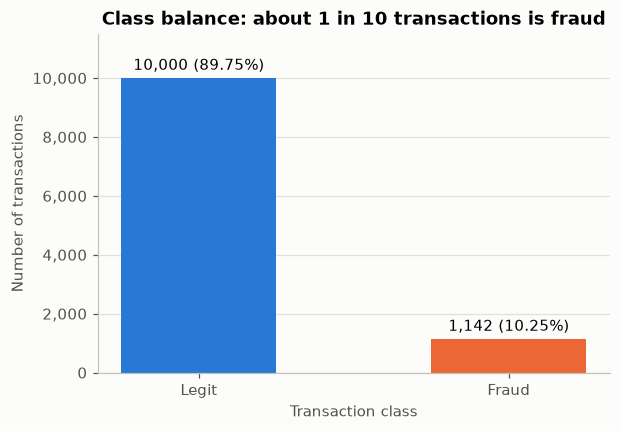

In [7]:
fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(class_counts.index, class_counts.values,
              color=[COLOR_LEGIT, COLOR_FRAUD], width=0.5)
ax.bar_label(bars, labels=[f"{n:,} ({p:.2%})" for n, p in zip(class_counts, class_share)],
             padding=3)
ax.set_title("Class balance: about 1 in 10 transactions is fraud")
ax.set_xlabel("Transaction class")
ax.set_ylabel("Number of transactions")
ax.set_ylim(0, class_counts.max() * 1.15)  # headroom so the bar labels don't hit the title
ax.yaxis.set_major_formatter("{x:,.0f}")
ax.grid(axis="x", visible=False)  # vertical gridlines add nothing on a bar chart

fig.savefig(FIGURES_DIR / "01_class_balance.png")
plt.show()

**Insight:** Fraud is 10.25% of this sample (1,142 of 11,142). Real mobile-money fraud is usually well under 1%, so this sample is heavily enriched with fraud. Even so, a "model" that calls every transaction legitimate would score 89.75% accuracy while catching zero fraud, which is why accuracy is not our headline metric.

### 2.2 Fraud by transaction type

Is fraud spread across all five transaction types, or concentrated in a few?

In [8]:
type_summary = df.groupby("type")["isFraud"].agg(total="size", fraud="sum")
type_summary["legit"] = type_summary["total"] - type_summary["fraud"]
type_summary["fraud_rate_%"] = (type_summary["fraud"] / type_summary["total"] * 100).round(2)
type_summary = type_summary.sort_values("total", ascending=False)
type_summary

,total,fraud,legit,fraud_rate_%
type,,,,
PAYMENT,5510,0,5510,0.00
CASH_IN,1951,0,1951,0.00
CASH_OUT,1871,578,1293,30.89
TRANSFER,1464,564,900,38.52
DEBIT,346,0,346,0.00


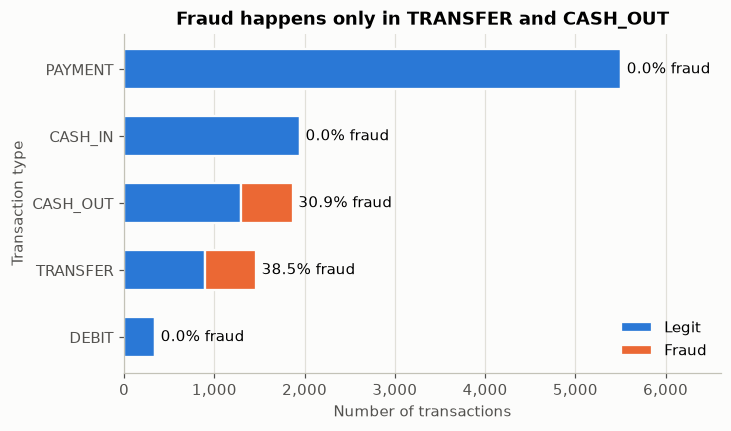

In [9]:
# barh draws from the bottom up, so sort ascending to put the biggest type on top
plot_data = type_summary.sort_values("total")

fig, ax = plt.subplots(figsize=(7, 4))
# The thin background-coloured edge leaves a small gap between the two segments
ax.barh(plot_data.index, plot_data["legit"], height=0.6, color=COLOR_LEGIT,
        edgecolor="#fcfcfb", linewidth=1.5, label="Legit")
ax.barh(plot_data.index, plot_data["fraud"], left=plot_data["legit"], height=0.6,
        color=COLOR_FRAUD, edgecolor="#fcfcfb", linewidth=1.5, label="Fraud")

for type_name, row in plot_data.iterrows():
    ax.text(row["total"] + 60, type_name, f"{row['fraud_rate_%']:.1f}% fraud", va="center")

ax.set_title("Fraud happens only in TRANSFER and CASH_OUT")
ax.set_xlabel("Number of transactions")
ax.set_ylabel("Transaction type")
ax.set_xlim(0, plot_data["total"].max() * 1.2)  # room for the text labels
ax.xaxis.set_major_formatter("{x:,.0f}")
ax.grid(axis="y", visible=False)
ax.legend(frameon=False, loc="lower right")

fig.savefig(FIGURES_DIR / "02_fraud_by_type.png")
plt.show()

**Insight:** Fraud appears only in TRANSFER (564 cases, 38.5% of transfers) and CASH_OUT (578 cases, 30.9%); PAYMENT, the most common type, along with CASH_IN and DEBIT, has no fraud at all. This matches how fraud works in this simulated data (take over an account, TRANSFER the money out, then CASH_OUT), so `type` will be a key feature. Caveat: zero fraud in this sample does not prove fraud is impossible in those types in the real world.

### 2.3 Transaction amounts

Are fraudulent transactions larger than legitimate ones? Amounts span from a few units to 10 million, so we plot them on a log scale. We compare across all types and again within TRANSFER and CASH_OUT, where fraud actually happens.

In [10]:
# Fraud only happens in these two types, so comparing within them is the fair test
risky_types = ["TRANSFER", "CASH_OUT"]
df_risky = df[df["type"].isin(risky_types)]

def amount_stats(data):
    return (data.groupby("isFraud")["amount"]
                .agg(["count", "median", "mean", "max"])
                .rename(index=class_labels))

pd.concat({"All types": amount_stats(df),
           "TRANSFER + CASH_OUT": amount_stats(df_risky)}).round(0).astype("int64")

count  median     mean       max
                    isFraud                                  
All types           Legit    10000   12725   101340   3776389
                    Fraud     1142  353179  1192629  10000000
TRANSFER + CASH_OUT Legit     2193  166736   292256   3776389
                    Fraud     1142  353179  1192629  10000000

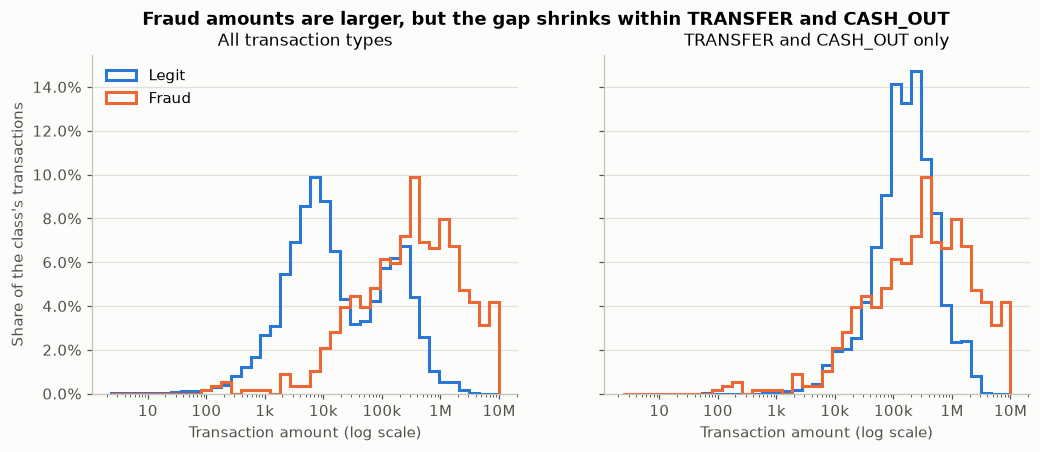

In [11]:
import numpy as np
from matplotlib.ticker import EngFormatter, PercentFormatter

# Bins evenly spaced on a log scale, so small and large amounts get equal room
bins = np.logspace(np.log10(df["amount"].min()), np.log10(df["amount"].max()), 40)

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharex=True, sharey=True)
panels = [("All transaction types", df), ("TRANSFER and CASH_OUT only", df_risky)]

for ax, (panel_title, data) in zip(axes, panels):
    for label, color in [(0, COLOR_LEGIT), (1, COLOR_FRAUD)]:
        amounts = data.loc[data["isFraud"] == label, "amount"]
        # Weights turn counts into each class's share, so the smaller fraud class
        # is not drowned out by 10,000 legit transactions
        ax.hist(amounts, bins=bins, weights=np.ones(len(amounts)) / len(amounts),
                histtype="step", linewidth=2, color=color, label=class_labels[label])
    ax.set_xscale("log")
    ax.xaxis.set_major_formatter(EngFormatter(sep=""))  # 1k, 10k, 1M instead of 10^3
    ax.set_title(panel_title, fontsize=11, fontweight="normal")
    ax.set_xlabel("Transaction amount (log scale)")
    ax.grid(axis="x", visible=False)

axes[0].set_ylabel("Share of the class's transactions")
axes[0].yaxis.set_major_formatter(PercentFormatter(1.0))
axes[0].legend(frameon=False, loc="upper left")
fig.suptitle("Fraud amounts are larger, but the gap shrinks within TRANSFER and CASH_OUT",
             fontweight="bold")

fig.savefig(FIGURES_DIR / "03_amount_distribution.png")
plt.show()

In [12]:
# The largest fraud amount is a suspiciously round number: how often does it occur?
df.loc[df["amount"] == 10_000_000, "isFraud"].value_counts().rename(index=class_labels)

isFraud
Fraud    14
Name: count, dtype: int64

**Insight:** Fraud amounts are much larger overall (median about 353K vs 12.7K for legit), but most of that gap comes from legit PAYMENTs being small. Within TRANSFER and CASH_OUT the median gap is only about 2x (353K vs 167K) and the two curves overlap heavily below 1M, so amount is a useful signal but not a clean separator on its own. Above 3.78M (the largest legit amount) every transaction is fraud, including 14 of exactly 10,000,000, which looks like a per-transaction cap in the simulator, with larger thefts split into 10M pieces.

### 2.4 Time: when do transactions happen?

`step` is the hour since the simulation started (1 to 95, about 4 days). Before looking for time-of-day patterns, check that both classes actually cover the same hours. If they don't, time would "predict" fraud only because of how the sample was built.

In [13]:
# Which hours (steps) does each class come from?
df.groupby("isFraud")["step"].agg(["min", "max", "nunique"]).rename(index=class_labels)

,min,max,nunique
isFraud,,,
Legit,1,7,7
Fraud,1,95,95


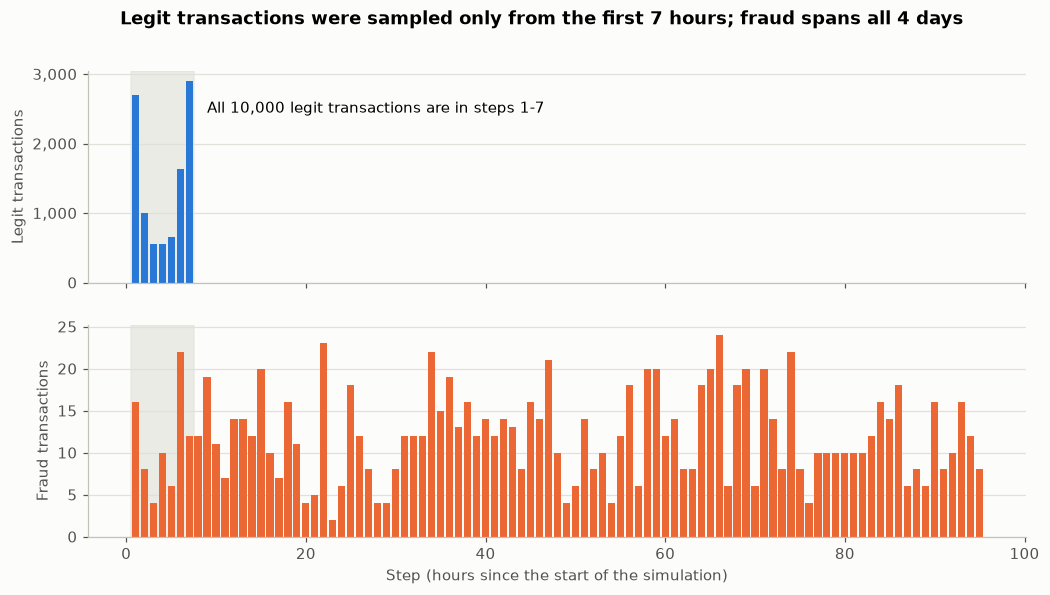

In [14]:
counts_by_step = pd.crosstab(df["step"], df["isFraud"]).rename(columns=class_labels)
LEGIT_LAST_STEP = df.loc[df["isFraud"] == 0, "step"].max()

# Two panels with their own y-axis: legit counts run into the thousands, fraud into the tens
fig, axes = plt.subplots(2, 1, figsize=(11, 5.5), sharex=True)
for ax, label, color in [(axes[0], "Legit", COLOR_LEGIT), (axes[1], "Fraud", COLOR_FRAUD)]:
    ax.bar(counts_by_step.index, counts_by_step[label], width=0.8, color=color)
    # Grey band marks the hours where legit transactions exist
    ax.axvspan(0.5, LEGIT_LAST_STEP + 0.5, color="#e1e0d9", alpha=0.6, zorder=0)
    ax.set_ylabel(f"{label} transactions")
    ax.yaxis.set_major_formatter("{x:,.0f}")
    ax.grid(axis="x", visible=False)

axes[0].text(LEGIT_LAST_STEP + 2, counts_by_step["Legit"].max() * 0.9,
             f"All 10,000 legit transactions are in steps 1-{LEGIT_LAST_STEP}", va="top")
axes[1].set_xlabel("Step (hours since the start of the simulation)")
fig.suptitle("Legit transactions were sampled only from the first 7 hours; fraud spans all 4 days",
             fontweight="bold")

fig.savefig(FIGURES_DIR / "04_transactions_by_step.png")
plt.show()

In [15]:
# Fraud rate where both classes exist (steps 1-7) vs where only fraud exists
in_legit_window = (df["step"] <= LEGIT_LAST_STEP).map({True: f"Steps 1-{LEGIT_LAST_STEP}",
                                                      False: f"Steps {LEGIT_LAST_STEP + 1}-95"})
window_summary = df.groupby(in_legit_window)["isFraud"].agg(transactions="size", fraud="sum")
window_summary["fraud_rate_%"] = (window_summary["fraud"] / window_summary["transactions"] * 100).round(2)
window_summary

,transactions,fraud,fraud_rate_%
step,,,
Steps 1-7,10078,78,0.77
Steps 8-95,1064,1064,100.00


In [16]:
# Within fraud only (it covers every hour): do fraudsters prefer certain hours of the day?
fraud_by_hour = (df.loc[df["isFraud"] == 1, "step"] % 24).value_counts()
print(f"Fraud cases per hour of day: min {fraud_by_hour.min()}, max {fraud_by_hour.max()}, "
      f"average {fraud_by_hour.mean():.0f}")

Fraud cases per hour of day: min 26, max 70, average 48


**Insight:** All 10,000 legit transactions come from the first 7 hours (steps 1-7), while fraud is spread over all 95 hours, so every transaction after hour 7 is fraud. This is how the sample was built, not how fraudsters behave: a model given `step`, hour or day would learn "late = fraud" and score almost perfectly for a meaningless reason. Within the fraud cases alone there is no strong time-of-day pattern. Inside steps 1-7, where both classes exist, the fraud rate is only 0.77%, close to real-world levels.

**Decision:** `step` is dropped from the model inputs and no hour or day features are created. A time-based train/test split is also ruled out (a test set from later hours would be 100% fraud), so Section 4 uses a stratified random split.

### 2.5 Balance behaviour

Fraud here means taking over an account and moving the money out. Does that show up in the balances, for example the whole balance being moved, or the account ending at zero? We compare fraud and legit within TRANSFER and CASH_OUT only.

In [17]:
# Each check is True/False per transaction; the mean of True/False is the share that is True.
# np.isclose instead of == because money stored as floats can be off by a tiny rounding error.
balance_checks = pd.DataFrame({
    "Amount equals the whole origin balance":
        np.isclose(df_risky["amount"], df_risky["oldbalanceOrg"]),
    "Origin balances add up (old - amount = new)":
        np.isclose(df_risky["oldbalanceOrg"] - df_risky["amount"], df_risky["newbalanceOrig"]),
    "Origin balance is 0 after the transaction":
        df_risky["newbalanceOrig"] == 0,
    "Origin balance was already 0 before":
        df_risky["oldbalanceOrg"] == 0,
    "Destination balance is 0 before and after":
        (df_risky["oldbalanceDest"] == 0) & (df_risky["newbalanceDest"] == 0),
}, index=df_risky.index)

balance_rates = (balance_checks.groupby(df_risky["isFraud"]).mean() * 100).T
balance_rates = balance_rates.rename(columns=class_labels).round(1)
balance_rates

isFraud,Legit,Fraud
Amount equals the whole origin balance,0.0,97.1
Origin balances add up (old - amount = new),9.0,97.3
Origin balance is 0 after the transaction,90.8,99.2
Origin balance was already 0 before,59.9,1.8
Destination balance is 0 before and after,0.0,47.5


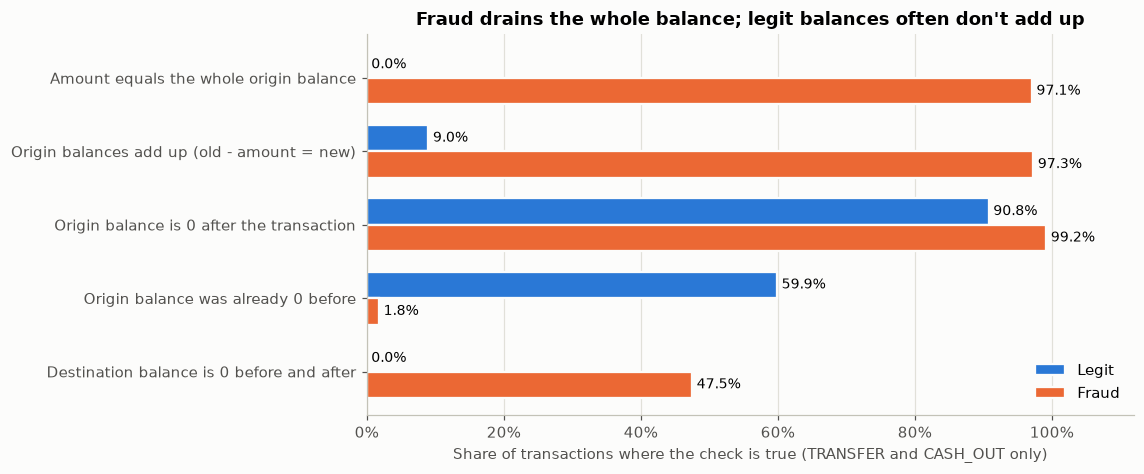

In [18]:
# barh draws bottom-up, so reverse the rows to keep the table's top-down order
plot_data = balance_rates.iloc[::-1]
y = np.arange(len(plot_data))
bar_height = 0.36

fig, ax = plt.subplots(figsize=(9, 4.5))
legit_bars = ax.barh(y + bar_height / 2, plot_data["Legit"], height=bar_height,
                     color=COLOR_LEGIT, edgecolor="#fcfcfb", linewidth=1.5, label="Legit")
fraud_bars = ax.barh(y - bar_height / 2, plot_data["Fraud"], height=bar_height,
                     color=COLOR_FRAUD, edgecolor="#fcfcfb", linewidth=1.5, label="Fraud")
for bars in (legit_bars, fraud_bars):
    ax.bar_label(bars, fmt="%.1f%%", padding=3, fontsize=9)

ax.set_yticks(y, plot_data.index)
ax.set_xlim(0, 112)  # room for the labels past 100%
ax.xaxis.set_major_formatter(PercentFormatter(100))
ax.set_xlabel("Share of transactions where the check is true (TRANSFER and CASH_OUT only)")
ax.set_title("Fraud drains the whole balance; legit balances often don't add up")
ax.grid(axis="y", visible=False)
ax.legend(frameon=False, loc="lower right")

fig.savefig(FIGURES_DIR / "05_balance_checks.png")
plt.show()

In [19]:
# The empty-destination pattern looked type-specific, so split it by type
dest_zero = balance_checks["Destination balance is 0 before and after"]
dest_zero_by_type = dest_zero.groupby([df_risky["type"], df_risky["isFraud"].map(class_labels)]).mean()
(dest_zero_by_type * 100).round(1).unstack()[["Legit", "Fraud"]]

isFraud,Legit,Fraud
type,,
CASH_OUT,0.0,0.2
TRANSFER,0.1,96.1


**Insight:** The strongest signal in the dataset: in 97.1% of fraud cases the amount equals the origin's entire balance (the account is drained exactly), against 0.0% of legit transactions. A naive check like "origin ends at zero" is useless (99.2% fraud vs 90.8% legit), because legit balances in this simulation often don't add up: about 60% of legit senders start with a zero balance and about 91% send more than they hold, which a real system would not allow. A destination balance of zero before and after marks 96% of fraudulent TRANSFERs but almost no CASH_OUTs. These are partly artefacts of the simulator, so balance-based features will push scores very high; later sections compare models with and without them.

### 2.6 Merchant vs customer destinations

Destination names starting with `M` are merchants and names starting with `C` are customers. Does fraud go to one kind more than the other, and does this add anything beyond the transaction type?

In [20]:
# Only the first letter of the destination name is used; the ID itself carries no meaning
dest_kind = df["nameDest"].str[0].map({"C": "Customer", "M": "Merchant"}).rename("destination")

# Which transaction types go to which kind of destination, split by class
# (rename 0/1 after building the table so Legit stays before Fraud)
pd.crosstab(df["type"], [dest_kind, df["isFraud"]]).rename(columns=class_labels, level=1)

destination Customer       Merchant
isFraud        Legit Fraud    Legit
type                               
CASH_IN         1951     0        0
CASH_OUT        1293   578        0
DEBIT            346     0        0
PAYMENT            0     0     5510
TRANSFER         900   564        0

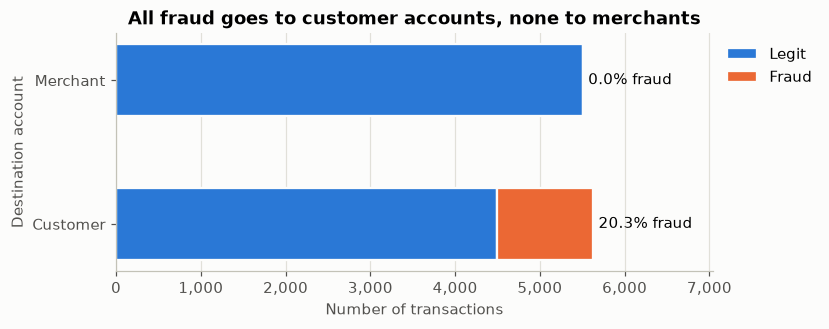

In [21]:
dest_summary = pd.crosstab(dest_kind, df["isFraud"]).rename(columns=class_labels)
dest_summary["total"] = dest_summary["Legit"] + dest_summary["Fraud"]
dest_summary["fraud_rate_%"] = (dest_summary["Fraud"] / dest_summary["total"] * 100).round(2)

fig, ax = plt.subplots(figsize=(7, 2.8))
ax.barh(dest_summary.index, dest_summary["Legit"], height=0.5, color=COLOR_LEGIT,
        edgecolor="#fcfcfb", linewidth=1.5, label="Legit")
ax.barh(dest_summary.index, dest_summary["Fraud"], left=dest_summary["Legit"], height=0.5,
        color=COLOR_FRAUD, edgecolor="#fcfcfb", linewidth=1.5, label="Fraud")

for kind, row in dest_summary.iterrows():
    ax.text(row["total"] + 60, kind, f"{row['fraud_rate_%']:.1f}% fraud", va="center")

ax.set_title("All fraud goes to customer accounts, none to merchants")
ax.set_xlabel("Number of transactions")
ax.set_ylabel("Destination account")
ax.set_xlim(0, dest_summary["total"].max() * 1.25)  # room for the text labels
ax.xaxis.set_major_formatter("{x:,.0f}")
ax.grid(axis="y", visible=False)
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(1, 1))  # outside, so it hides no bars

fig.savefig(FIGURES_DIR / "06_destination_kind.png")
plt.show()

In [22]:
# The data description says merchants have no balance information: confirm it
merchants = df[dest_kind == "Merchant"]
merchant_dest_zero = (merchants["oldbalanceDest"] == 0) & (merchants["newbalanceDest"] == 0)
print(f"Merchant destinations with zero balance before and after: {merchant_dest_zero.mean():.0%}")

Merchant destinations with zero balance before and after: 100%


**Insight:** All 1,142 fraud cases send money to customer accounts (20.3% of customer-bound transactions are fraud) and none go to merchants, which fits the takeover pattern: move the money to an account the fraudster controls. But merchants appear only in PAYMENT transactions, so "destination is a merchant" carries exactly the same information as "type is PAYMENT" and adds nothing beyond `type`. Merchant balances are always zero, confirming the data description that merchants have no balance information.

### 2.7 Correlations

How strongly do the numeric columns move together, and how does each relate to fraud? Very high correlations between features mean redundancy, which matters for linear models. We use Spearman (rank) correlation because amounts and balances are extremely skewed, and compare all types with TRANSFER and CASH_OUT only.

In [23]:
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap

# step is excluded: we decided in 2.4 not to use it
numeric_cols = ["amount", "oldbalanceOrg", "newbalanceOrig",
                "oldbalanceDest", "newbalanceDest", "isFraud"]

# Spearman works on ranks, so the few multi-million values cannot dominate the result
corr_all = df[numeric_cols].corr(method="spearman")
corr_risky = df_risky[numeric_cols].corr(method="spearman")

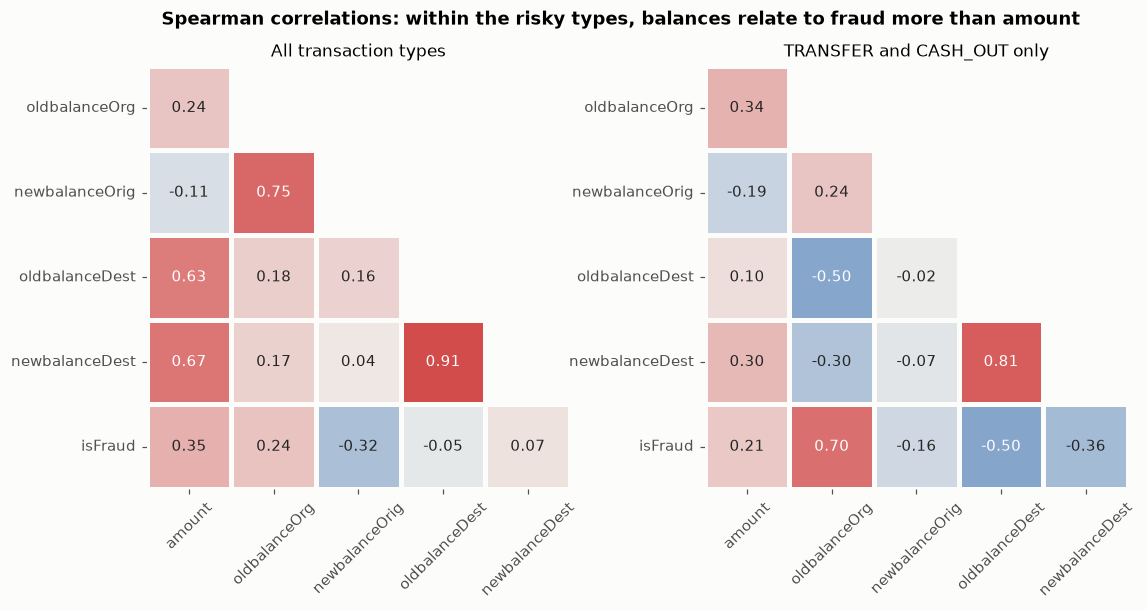

In [24]:
# Diverging colours: blue = move in opposite directions, grey = unrelated, red = move together
diverging_cmap = LinearSegmentedColormap.from_list("blue_grey_red", ["#1c5cab", "#f0efec", "#d03b3b"])

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
panels = [("All transaction types", corr_all), ("TRANSFER and CASH_OUT only", corr_risky)]

for ax, (panel_title, corr) in zip(axes, panels):
    # Each pair appears twice and every column correlates 1.00 with itself, so keep only
    # the lower triangle: drop the first row and last column, then hide the cells above
    trimmed = corr.iloc[1:, :-1]
    mask = np.triu(np.ones_like(trimmed, dtype=bool), k=1)
    # Every cell is labelled with its value, so a colour bar is not needed
    sns.heatmap(trimmed, mask=mask, cmap=diverging_cmap, vmin=-1, vmax=1, annot=True, fmt=".2f",
                square=True, linewidths=2, linecolor="#fcfcfb", cbar=False, ax=ax)
    ax.set_title(panel_title, fontsize=11, fontweight="normal")
    ax.tick_params(axis="x", rotation=45)
    ax.grid(False)

fig.suptitle("Spearman correlations: within the risky types, balances relate to fraud more than amount",
             fontweight="bold")

fig.savefig(FIGURES_DIR / "07_correlation_heatmap.png")
plt.show()

In [25]:
# The column that matters most: how each raw column relates to fraud
pd.DataFrame({"All types": corr_all["isFraud"],
              "TRANSFER + CASH_OUT": corr_risky["isFraud"]}).drop("isFraud").round(2)

,All types,TRANSFER + CASH_OUT
amount,0.35,0.21
oldbalanceOrg,0.24,0.70
newbalanceOrig,-0.32,-0.16
oldbalanceDest,-0.05,-0.50
newbalanceDest,0.07,-0.36


In [26]:
# Why Spearman: a few huge fraud drains (amount = the entire, very large balance)
# inflate the ordinary Pearson correlation between amount and origin balance
pearson_risky = df_risky[numeric_cols].corr(method="pearson")
print("amount vs oldbalanceOrg, TRANSFER + CASH_OUT: "
      f"Pearson {pearson_risky.loc['amount', 'oldbalanceOrg']:.2f}, "
      f"Spearman {corr_risky.loc['amount', 'oldbalanceOrg']:.2f}")

amount vs oldbalanceOrg, TRANSFER + CASH_OUT: Pearson 0.93, Spearman 0.34


**Why this matters for feature selection:** this heatmap is for understanding the data, not for choosing features. Two uses. First, the `isFraud` row shows which columns relate to fraud and in which direction. Second, pairs of columns that correlate strongly (for example `oldbalanceDest` and `newbalanceDest` at 0.91) carry nearly the same information, which suggests replacing them with a difference feature in Section 3. Features will be chosen in Section 4 using cross-validated model performance, since correlation misses interactions such as "amount equals the whole origin balance".

**Insight:** Within TRANSFER and CASH_OUT the balances relate to fraud more strongly than the amount does (origin balance before: +0.70, destination balance before: -0.50, amount: +0.21), partly because of the simulator quirk from 2.5 where most legit senders start at zero. Old and new destination balances are highly correlated (0.91 overall), so they largely repeat each other. Correlation also has a blind spot: the strongest signal found in 2.5 ("amount equals the whole origin balance") is a relationship between two columns that no single correlation can show, which is why Section 3 builds features that combine columns. Spearman (rank) correlation is used because a few multi-million transactions distort the ordinary Pearson version.

## 3. Preprocessing and feature engineering

Balance-error and flag features, time features, one-hot encoding of `type`, and dropping the raw name IDs.

### 3.1 The feature class

All feature engineering lives in one class, `FraudFeatures`, in `model/features.py`. It is the only code outside this notebook: the saved pipeline contains this class, so the API must be able to import it. It:

- keeps `type`, `amount` and the four raw balances;
- drops `step` (sampling artefact, see 2.4), `nameOrig` and `nameDest` (unique IDs);
- adds four balance features based on the EDA in 2.5:
  - `error_balance_orig` = newbalanceOrig + amount - oldbalanceOrg (0 when the origin balance adds up)
  - `error_balance_dest` = oldbalanceDest + amount - newbalanceDest (0 when the destination balance adds up)
  - `drains_whole_balance` = 1 when the amount equals the entire origin balance
  - `dest_zero_before_after` = 1 when the destination balance is 0 before and after

Setting `include_balance_features=False` leaves the four engineered features out, so Section 4 can show how much the results depend on them. The "is merchant" and "origin emptied" flags were left out because the EDA showed they add nothing (2.5, 2.6).

In [27]:
import sys

# The feature class lives in model/features.py (one level up from notebooks/),
# so the saved pipeline can be loaded by the API later with the same code
PROJECT_ROOT = Path("..").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

from model.features import BALANCE_FEATURES, DROPPED_COLUMNS, RAW_COLUMNS, FraudFeatures

In [28]:
# X = raw inputs exactly as a new transaction would arrive; y = the label to predict
X = df[RAW_COLUMNS]
y = df["isFraud"]
print(f"X: {X.shape[0]:,} rows x {X.shape[1]} raw columns   y: {y.shape[0]:,} labels")

X: 11,142 rows x 9 raw columns   y: 11,142 labels


In [29]:
# Try the class on four rows: two fraud and two legit, all TRANSFER or CASH_OUT
example_rows = pd.concat([
    X[y == 1].head(2),
    X[(y == 0) & X["type"].isin(risky_types)].head(2),
])
print("Labels:", y[example_rows.index].map(class_labels).tolist())
FraudFeatures().fit_transform(example_rows)

Labels: ['Fraud', 'Fraud', 'Legit', 'Legit']


,type,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,error_balance_orig,error_balance_dest,drains_whole_balance,dest_zero_before_after
0,TRANSFER,181.00,181.0,0.0,0.0,0.00,0.00,181.0,1,1
1,CASH_OUT,181.00,181.0,0.0,21182.0,0.00,0.00,21363.0,1,0
1155,CASH_OUT,229133.94,15325.0,0.0,5083.0,51513.44,213808.94,182703.5,0,0
1159,TRANSFER,215310.30,705.0,0.0,22425.0,0.00,214605.30,237735.3,0,0


In [30]:
# Sanity check: within TRANSFER and CASH_OUT, the new flags should match the EDA in 2.5
# (whole balance drained: 97.1% fraud vs 0.0% legit). Safe on all rows: nothing is fitted.
features_all = FraudFeatures().fit_transform(X)
risky_rows = X["type"].isin(risky_types)
flag_columns = ["drains_whole_balance", "dest_zero_before_after"]
flag_rates = features_all.loc[risky_rows, flag_columns].groupby(y[risky_rows]).mean() * 100
flag_rates.rename(index=class_labels).round(1)

,drains_whole_balance,dest_zero_before_after
isFraud,,
Legit,0.0,0.0
Fraud,97.1,47.5


**What this shows:** the class turns 9 raw columns into 10 features: 6 raw columns kept and 4 engineered balance features. `step`, `nameOrig` and `nameDest` are gone. On the full data the new flags reproduce the EDA findings, which confirms the code does what we intended. Because every feature is computed from its own row, running the class on all rows here leaks nothing; the encoder in 3.2 is different and must only be fitted after the split.

### 3.2 Encoding `type` and the full preprocessor

`type` is text, so it is one-hot encoded: one 0/1 column per transaction type. Numbering the types 1-5 instead would invent an order that does not exist.

The preprocessor chains two steps in a scikit-learn `Pipeline`: `FraudFeatures` (3.1), then a `ColumnTransformer` that one-hot encodes `type` and passes the numeric columns through. Unlike the feature class, the encoder *learns* something when fitted (which types exist), so it must only be fitted on training data. Scaling is left out on purpose: Logistic Regression needs it and tree models do not, so it is added per model in Section 4.

In [31]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder


def build_preprocessor(include_balance_features=True):
    """Raw transaction columns in, model-ready numbers out (no scaling: that is model-specific)."""
    encode = ColumnTransformer(
        # One 0/1 column per type; an unseen type becomes all zeros instead of an error
        [("type", OneHotEncoder(handle_unknown="ignore", sparse_output=False), ["type"])],
        remainder="passthrough",          # numeric features go through unchanged
        verbose_feature_names_out=False,  # keep names like "amount", not "remainder__amount"
    )
    preprocessor = Pipeline([
        ("features", FraudFeatures(include_balance_features=include_balance_features)),
        ("encode", encode),
    ])
    # Output a DataFrame with column names, so later steps (and SHAP) can show feature names
    return preprocessor.set_output(transform="pandas")

In [32]:
# Demo only: fit on the four example rows to see what the encoder learns.
# The real fit happens in Section 4, on the training split only.
demo_preprocessor = build_preprocessor().fit(example_rows)
learned_types = demo_preprocessor.named_steps["encode"].named_transformers_["type"].categories_[0]
print("Types the encoder learned:", list(learned_types))

Types the encoder learned: ['CASH_OUT', 'TRANSFER']


In [33]:
# A PAYMENT row was not among the four rows the encoder saw: no crash, its type columns are all 0
payment_row = X[X["type"] == "PAYMENT"].head(1)
demo_preprocessor.transform(pd.concat([example_rows, payment_row]))

,type_CASH_OUT,type_TRANSFER,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,error_balance_orig,error_balance_dest,drains_whole_balance,dest_zero_before_after
0,0.0,1.0,181.00,181.0,0.00,0.0,0.00,0.00,181.00,1,1
1,1.0,0.0,181.00,181.0,0.00,21182.0,0.00,0.00,21363.00,1,0
1155,1.0,0.0,229133.94,15325.0,0.00,5083.0,51513.44,213808.94,182703.50,0,0
1159,0.0,1.0,215310.30,705.0,0.00,22425.0,0.00,214605.30,237735.30,0,0
1142,0.0,0.0,9839.64,170136.0,160296.36,0.0,0.00,0.00,9839.64,0,1


**What this shows:** fitted on four rows that only contain TRANSFER and CASH_OUT, the encoder learned just those two types. A PAYMENT row it has never seen gets 0 in both type columns instead of an error, which is what `handle_unknown="ignore"` is for. This is also why the encoder may only be fitted on the training data: what it learns depends on the rows it is fitted on. In Section 4 the whole preprocessor is fitted on the training split, which contains all five types, giving 14 model inputs (10 without the balance features). The PAYMENT row also shows that merchant destinations, which have no balances, always get `dest_zero_before_after` = 1 and `error_balance_dest` = the amount; the type columns let the model tell those apart from fraud.

### 3.3 Checking the new features

Two questions: do the engineered features separate fraud better than the raw columns, and do any features repeat each other?

For separation we use a **single-feature ROC-AUC**: rank all transactions by one feature and ask how often a random fraud case ranks above a random legit one. 0.5 is a coin flip, 1.0 is perfect. A feature where *low* values mean fraud gets an AUC below 0.5, so we also report the direction-free version, max(AUC, 1 - AUC). This is a check on features already designed from the EDA, not a way of choosing features: choosing features by scores on all rows would let the test rows influence the model.

In [34]:
from sklearn.metrics import roc_auc_score

# Numeric features within TRANSFER and CASH_OUT, where fraud actually happens
risky_features = features_all.loc[risky_rows].drop(columns="type")
y_risky = y[risky_rows]

single_auc = risky_features.apply(lambda column: roc_auc_score(y_risky, column))
separation = pd.DataFrame({
    "auc": single_auc,
    # An AUC of 0.1 separates as well as 0.9, just in the other direction
    "separation": np.maximum(single_auc, 1 - single_auc),
    "fraud_when_value_is": np.where(single_auc >= 0.5, "higher", "lower"),
    "engineered": single_auc.index.isin(BALANCE_FEATURES),
}).sort_values("separation", ascending=False)
separation.round(3)

,auc,separation,fraud_when_value_is,engineered
drains_whole_balance,0.986,0.986,higher,True
error_balance_orig,0.056,0.944,lower,True
oldbalanceOrg,0.914,0.914,higher,False
oldbalanceDest,0.197,0.803,lower,False
dest_zero_before_after,0.738,0.738,higher,True
newbalanceDest,0.283,0.717,lower,False
error_balance_dest,0.672,0.672,higher,True
amount,0.629,0.629,higher,False
newbalanceOrig,0.458,0.542,lower,False


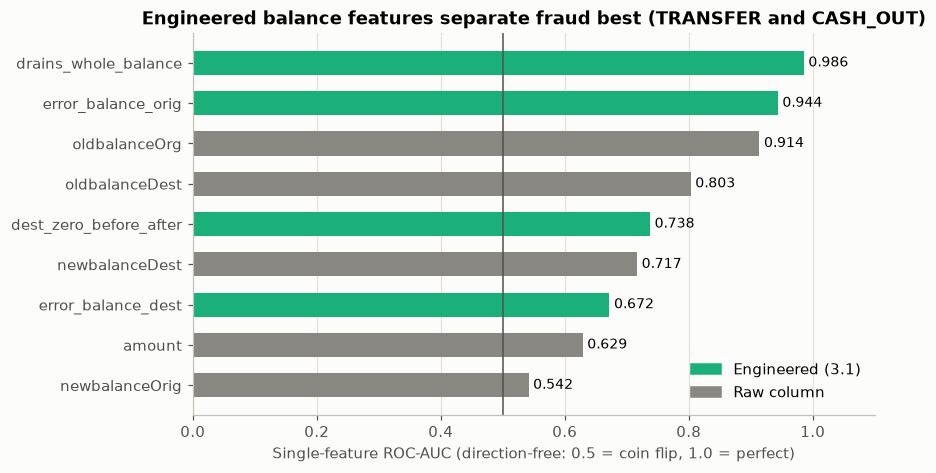

In [35]:
from matplotlib.patches import Patch

# Green for engineered features, grey for raw columns: blue and orange stay reserved for legit/fraud
COLOR_ENGINEERED = "#1baf7a"
COLOR_RAW = "#898781"

plot_data = separation.iloc[::-1]  # barh draws bottom-up; keep the table's order top-down
bar_colors = np.where(plot_data["engineered"], COLOR_ENGINEERED, COLOR_RAW)

fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.barh(plot_data.index, plot_data["separation"], height=0.6, color=bar_colors)
ax.bar_label(bars, fmt="%.3f", padding=3, fontsize=9)
ax.axvline(0.5, color="#52514e", linewidth=1)  # the coin-flip line

ax.set_title("Engineered balance features separate fraud best (TRANSFER and CASH_OUT)")
ax.set_xlabel("Single-feature ROC-AUC (direction-free: 0.5 = coin flip, 1.0 = perfect)")
ax.set_xlim(0, 1.1)
ax.grid(axis="y", visible=False)
ax.legend(handles=[Patch(color=COLOR_ENGINEERED, label="Engineered (3.1)"),
                   Patch(color=COLOR_RAW, label="Raw column")],
          frameon=False, loc="lower right")

fig.savefig(FIGURES_DIR / "08_feature_separation.png")
plt.show()

In [36]:
# Redundancy check: the most strongly correlated pairs of features (each pair listed once)
feature_corr = risky_features.corr(method="spearman")
pairs = feature_corr.where(np.triu(np.ones(feature_corr.shape, dtype=bool), k=1)).stack()
strongest = pairs.reindex(pairs.abs().sort_values(ascending=False).index)
strongest.rename("spearman").round(2).head(6).to_frame()

spearman
oldbalanceDest     newbalanceDest              0.81
error_balance_orig drains_whole_balance       -0.76
oldbalanceOrg      drains_whole_balance        0.71
                   error_balance_orig         -0.71
newbalanceDest     dest_zero_before_after     -0.62
                   error_balance_dest         -0.61

**Insight:** The engineered features separate fraud best: `drains_whole_balance` alone reaches 0.986 and `error_balance_orig` 0.944 (fraud has near-zero error), while `amount` manages only 0.629. `oldbalanceOrg` also scores high (0.914), but mostly because of the simulator quirk where legit senders start at zero. One feature already separating the classes almost perfectly means the models in Section 4 will likely score close to perfect, which says more about this simulated data than about real-world performance, so Section 4 also trains without the balance features. No pair is a duplicate (strongest: old vs new destination balance at 0.81), so all features are kept; `drains_whole_balance` and `error_balance_orig` overlap (-0.76) but each carries something the other does not.

## 4. Train/test split and baseline model

Split the data before fitting anything, then fit a baseline Logistic Regression inside a Pipeline.

### 4.1 Train/test split

The data is split **before anything is fitted**: 80% for training (and cross-validation), 20% held back as a test set that is used only once, at the end. The split is **stratified** on `isFraud`, so both parts keep the same 10.25% fraud rate. A time-based split is not possible here: steps after 7 contain only fraud (2.4).

In [37]:
from sklearn.model_selection import train_test_split

TEST_SIZE = 0.20

# stratify=y keeps the 10.25% fraud rate in both parts; a time-based split is
# impossible here because later steps contain only fraud (see 2.4)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_STATE
)

In [38]:
# Check that stratification worked: the fraud rate should be the same in both parts
split_summary = pd.DataFrame({
    "rows": [len(y_train), len(y_test)],
    "fraud": [y_train.sum(), y_test.sum()],
    "fraud_rate_%": [y_train.mean() * 100, y_test.mean() * 100],
}, index=["train", "test"]).round(2)
split_summary

,rows,fraud,fraud_rate_%
train,8913,914,10.25
test,2229,228,10.23


In [39]:
# Same check by transaction type: all five types should appear in both parts
fraud_by_type_split = pd.DataFrame({
    "train_rows": X_train["type"].value_counts(),
    "train_fraud": y_train.groupby(X_train["type"]).sum(),
    "test_rows": X_test["type"].value_counts(),
    "test_fraud": y_test.groupby(X_test["type"]).sum(),
})
fraud_by_type_split

,train_rows,train_fraud,test_rows,test_fraud
type,,,,
CASH_IN,1544,0,407,0
CASH_OUT,1487,454,384,124
DEBIT,282,0,64,0
PAYMENT,4403,0,1107,0
TRANSFER,1197,460,267,104


**What this shows:** both parts keep the 10.25% fraud rate and contain all five transaction types, with fraud still only in TRANSFER and CASH_OUT. The split is fixed by `random_state=42`, so it is the same every run. From here on, everything (cross-validation, tuning, imbalance handling, threshold choice) uses `X_train` / `y_train` only; `X_test` / `y_test` are used once, for the final evaluation in Section 6.

### 4.2 Baseline: Logistic Regression

A simple, explainable baseline that every later model must beat. The pipeline is: preprocessor (3.2), then `StandardScaler` (Logistic Regression is sensitive to scale: amounts in the millions would swamp the 0/1 flags), then `LogisticRegression` with `class_weight="balanced"` to handle the 10% fraud rate.

It is scored with **stratified 5-fold cross-validation on the training set only**: the training data is split into 5 parts, the model is trained on 4 and validated on the 5th, rotating 5 times. Because every step sits inside one pipeline, the scaler and encoder are re-fitted on each training fold, so no validation data leaks in. **PR-AUC** decides; ROC-AUC, precision, recall and F1 are shown alongside. It is run with and without the balance features.

In [40]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler

# Stratified 5-fold CV: every fold keeps the 10% fraud rate. Used for every model in Sections 4-5.
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
SCORING = {
    "pr_auc": "average_precision",  # the selection metric
    "roc_auc": "roc_auc",
    "precision": "precision",       # precision, recall and F1 use the default 0.5 threshold
    "recall": "recall",
    "f1": "f1",
}


def build_model_pipeline(model, include_balance_features=True, scale=False):
    """Preprocessor from 3.2, optional scaling (needed by linear models only), then the model."""
    steps = [("preprocess", build_preprocessor(include_balance_features))]
    if scale:
        steps.append(("scale", StandardScaler()))
    steps.append(("model", model))
    return Pipeline(steps)


def cv_scores(pipeline, name):
    """Mean validation scores over the 5 folds of the TRAINING set (the test set is never touched)."""
    results = cross_validate(pipeline, X_train, y_train, cv=CV, scoring=SCORING,
                             return_train_score=True)
    row = {metric: results[f"test_{metric}"].mean() for metric in SCORING}
    row["pr_auc_std"] = results["test_pr_auc"].std()        # how much folds disagree
    row["train_pr_auc"] = results["train_pr_auc"].mean()    # far above pr_auc = overfitting
    return pd.Series(row, name=name)

In [41]:
def logistic_regression():
    # class_weight="balanced": a mistake on a fraud case counts ~9x more than on a legit case
    return LogisticRegression(class_weight="balanced", max_iter=1000, random_state=RANDOM_STATE)


baseline_results = pd.DataFrame([
    cv_scores(build_model_pipeline(logistic_regression(), include_balance_features=True, scale=True),
              "LogReg, with balance features"),
    cv_scores(build_model_pipeline(logistic_regression(), include_balance_features=False, scale=True),
              "LogReg, without balance features"),
]).round(3)
baseline_results

,pr_auc,roc_auc,precision,recall,f1,pr_auc_std,train_pr_auc
"LogReg, with balance features",0.994,0.999,1.000,0.979,0.989,0.003,0.995
"LogReg, without balance features",0.915,0.987,0.433,0.988,0.602,0.016,0.917


**Insight:** Even the simplest model is near-perfect with the balance features (PR-AUC 0.994, precision 1.000, recall 0.979), as 3.3 predicted: the engineered drain and balance-error features make this simulated data easy. Without them, PR-AUC drops to 0.915 and, at the default 0.5 threshold, precision falls to 0.433: the model still catches 98.8% of fraud but raises more false alarms than real catches. That precision is partly a threshold effect (class weights push probabilities up, and 0.5 is not tuned yet), which Section 7 addresses with a cost-based threshold. Training and validation PR-AUC are almost identical in both versions, so the baseline is not overfitting. For reference, a model that guesses randomly scores a PR-AUC of about 0.10 (the fraud rate).

### 4.3 Handling the imbalance: none vs class weights vs SMOTE

The same baseline, three ways:
- **No adjustment:** the model sees 10% fraud as it is.
- **Class weights:** mistakes on fraud count about 9x more during training (used in 4.2).
- **SMOTE:** creates synthetic fraud cases by blending real fraud cases with their nearest fraud neighbours until the classes are balanced.

SMOTE is a leakage trap: if synthetic rows were created before the split or before cross-validation, copies of validation fraud would end up in training. Here it sits inside an imbalanced-learn `Pipeline`, which only resamples while fitting, so it only ever sees the training folds.

In [42]:
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline


def build_smote_pipeline(model, include_balance_features=True):
    """Like build_model_pipeline(scale=True), with SMOTE between scaling and the model.

    imbalanced-learn's Pipeline only resamples while fitting, so every validation fold stays
    100% real data. It does not accept a nested Pipeline, so the preprocessor's two steps
    are passed in one by one. SMOTE comes after scaling because it works with distances.
    """
    steps = build_preprocessor(include_balance_features).steps
    return ImbPipeline(steps + [
        ("scale", StandardScaler()),
        ("smote", SMOTE(random_state=RANDOM_STATE)),
        ("model", model),
    ])

In [43]:
def logistic_regression_unweighted():
    return LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)


imbalance_rows = []
for include in (True, False):
    features_label = "with balance features" if include else "without balance features"
    imbalance_rows += [
        cv_scores(build_model_pipeline(logistic_regression_unweighted(), include, scale=True),
                  ("No adjustment", features_label)),
        cv_scores(build_model_pipeline(logistic_regression(), include, scale=True),
                  ("Class weights", features_label)),
        cv_scores(build_smote_pipeline(logistic_regression_unweighted(), include),
                  ("SMOTE", features_label)),
    ]

imbalance_results = pd.DataFrame(imbalance_rows).round(3)
imbalance_results.index = pd.MultiIndex.from_tuples(imbalance_results.index, names=["method", "features"])
imbalance_results.swaplevel().sort_index(level=0, sort_remaining=False)

pr_auc  roc_auc  precision  recall  \
features                 method                                              
with balance features    No adjustment   0.995    0.999      1.000   0.979   
                         Class weights   0.994    0.999      1.000   0.979   
                         SMOTE           0.994    0.999      1.000   0.979   
without balance features No adjustment   0.904    0.984      0.979   0.544   
                         Class weights   0.915    0.987      0.433   0.988   
                         SMOTE           0.930    0.990      0.467   0.989   

                                           f1  pr_auc_std  train_pr_auc  
features                 method                                          
with balance features    No adjustment  0.989       0.003         0.995  
                         Class weights  0.989       0.003         0.995  
                         SMOTE          0.989       0.002         0.995  
without balance features No adjustment  0.699       0.016         0.905  
                         Class weights  0.602       0.016         0.917  
                         SMOTE          0.634       0.013         0.931

**Insight:** With the balance features, the imbalance method makes no difference (PR-AUC 0.994-0.995 for all three): the data is easy enough that the model separates the classes regardless. Without them, SMOTE ranks best (PR-AUC 0.930 vs 0.915 for class weights and 0.904 for no adjustment), although the gap to class weights is about the size of the fold-to-fold spread. The bigger visible effect is on the 0.5-threshold metrics: with no adjustment the model is cautious (precision 0.979, but recall only 0.544), while class weights and SMOTE flip it to catching almost all fraud (recall 0.99) at the cost of many false alarms. That trade-off is exactly what the cost-based threshold in Section 7 will settle, so PR-AUC, which does not depend on the threshold, is the fairer comparison here.

**Decision:** class weights are used for all models from here on. They tie with SMOTE where it matters (with the balance features), the SMOTE advantage without them is within the fold-to-fold noise, every model in Section 5 supports class weights natively, and no synthetic data has to be explained.

## 5. Model comparison and tuning

Compare Decision Tree, Random Forest, Gradient Boosting, XGBoost and LightGBM with cross-validation, handle class imbalance, and tune the best models.

### 5.1 Comparing classifiers

Six models, each scored with the same stratified 5-fold CV on the training set and class weights for the imbalance (decision in 4.3):

- **Logistic Regression:** the 4.2 baseline (with scaling).
- **Decision Tree:** one set of if/else rules; easy to read, overfits easily.
- **Random Forest:** many trees on random subsets of rows and features, averaged.
- **Gradient Boosting:** trees built one after another, each correcting the previous ones. scikit-learn's `HistGradientBoostingClassifier` is used because, unlike the classic `GradientBoostingClassifier`, it supports class weights.
- **XGBoost** and **LightGBM:** fast, widely used gradient-boosting libraries. XGBoost takes `scale_pos_weight` (legit count / fraud count) instead of class weights.

Tree models need no scaling: they split on thresholds, so a column's scale changes nothing.

Each model is run on **three feature sets**, to show where the performance comes from:
1. **all features** (14 inputs);
2. **no engineered features**: the 4 balance features from 3.1 switched off (10 inputs);
3. **type + amount only**: no balance columns at all (6 inputs). Experiment only; not a candidate for the final model.

In [44]:
from lightgbm import LGBMClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier

# XGBoost's version of class weights: how many legit cases per fraud case (training set only)
SCALE_POS_WEIGHT = (y_train == 0).sum() / (y_train == 1).sum()
print(f"scale_pos_weight = {SCALE_POS_WEIGHT:.2f}")

# name -> (function that returns a fresh model, needs scaling?)
MODELS = {
    "Logistic Regression": (logistic_regression, True),
    "Decision Tree": (lambda: DecisionTreeClassifier(class_weight="balanced", random_state=RANDOM_STATE), False),
    "Random Forest": (lambda: RandomForestClassifier(n_estimators=300, class_weight="balanced",
                                                     n_jobs=-1, random_state=RANDOM_STATE), False),
    "Gradient Boosting": (lambda: HistGradientBoostingClassifier(class_weight="balanced",
                                                                 random_state=RANDOM_STATE), False),
    "XGBoost": (lambda: XGBClassifier(n_estimators=300, scale_pos_weight=SCALE_POS_WEIGHT,
                                      eval_metric="logloss", n_jobs=-1, random_state=RANDOM_STATE), False),
    "LightGBM": (lambda: LGBMClassifier(class_weight="balanced", verbose=-1,
                                        random_state=RANDOM_STATE), False),
}

scale_pos_weight = 8.75


In [45]:
def build_type_amount_preprocessor():
    """Experiment only: type (one-hot) + amount, with no balance columns at all."""
    return ColumnTransformer(
        [("type", OneHotEncoder(handle_unknown="ignore", sparse_output=False), ["type"]),
         ("amount", "passthrough", ["amount"])],
        verbose_feature_names_out=False,
    ).set_output(transform="pandas")


FEATURE_SETS = {
    "all features": lambda: build_preprocessor(include_balance_features=True),
    "no engineered features": lambda: build_preprocessor(include_balance_features=False),
    "type + amount only": build_type_amount_preprocessor,
}


def build_pipeline_for(model, feature_set, scale=False):
    steps = [("preprocess", FEATURE_SETS[feature_set]())]
    if scale:
        steps.append(("scale", StandardScaler()))
    steps.append(("model", model))
    return Pipeline(steps)

In [46]:
# 6 models x 3 feature sets = 18 cross-validation runs, all on the training set (about a minute)
comparison_rows = []
for model_name, (make_model, needs_scaling) in MODELS.items():
    for feature_set in FEATURE_SETS:
        pipeline = build_pipeline_for(make_model(), feature_set, scale=needs_scaling)
        comparison_rows.append(cv_scores(pipeline, (model_name, feature_set)))

comparison_results = pd.DataFrame(comparison_rows)
comparison_results.index = pd.MultiIndex.from_tuples(comparison_results.index,
                                                     names=["model", "feature_set"])

# PR-AUC (the selection metric) side by side: one row per model, one column per feature set
pr_auc_table = comparison_results["pr_auc"].unstack().loc[list(MODELS), list(FEATURE_SETS)]
pr_auc_table.round(3)

feature_set,all features,no engineered features,type + amount only
model,,,
Logistic Regression,0.994,0.915,0.597
Decision Tree,0.974,0.916,0.344
Random Forest,0.995,0.994,0.514
Gradient Boosting,0.994,0.995,0.659
XGBoost,0.995,0.993,0.656
LightGBM,0.994,0.995,0.662


In [47]:
# Full scores with all features; train_pr_auc of 1.000 means the model fits its training folds perfectly
comparison_results.xs("all features", level="feature_set").round(3)

,pr_auc,roc_auc,precision,recall,f1,pr_auc_std,train_pr_auc
model,,,,,,,
Logistic Regression,0.994,0.999,1.000,0.979,0.989,0.003,0.995
Decision Tree,0.974,0.991,0.989,0.982,0.986,0.008,1.000
Random Forest,0.995,0.998,0.996,0.984,0.990,0.003,1.000
Gradient Boosting,0.994,0.995,0.996,0.985,0.990,0.004,1.000
XGBoost,0.995,0.997,0.995,0.985,0.990,0.004,1.000
LightGBM,0.994,0.995,0.998,0.985,0.991,0.005,1.000


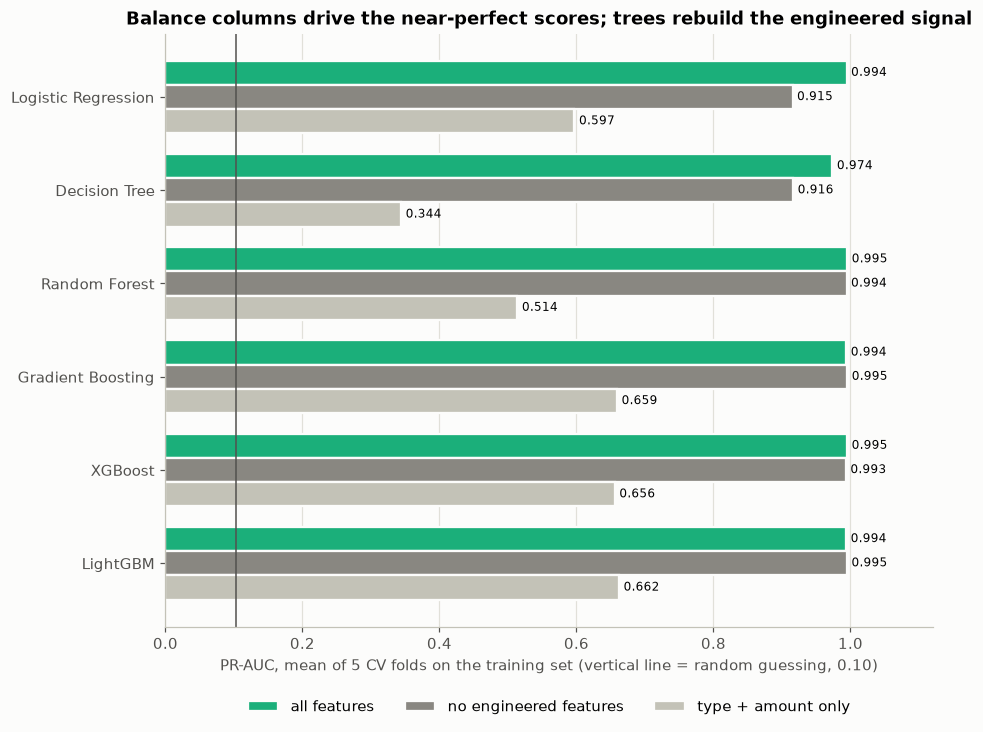

In [48]:
# Less information -> lighter colour: green = all features (as in 3.3), greys = fewer features
FEATURE_SET_COLORS = {
    "all features": COLOR_ENGINEERED,
    "no engineered features": COLOR_RAW,
    "type + amount only": "#c3c2b7",
}

plot_data = pr_auc_table.iloc[::-1]  # barh draws bottom-up; keep the table's order top-down
y_positions = np.arange(len(plot_data))
bar_height = 0.26

fig, ax = plt.subplots(figsize=(9, 7))
for i, (feature_set, color) in enumerate(FEATURE_SET_COLORS.items()):
    offset = (1 - i) * bar_height  # first feature set on top within each group
    bars = ax.barh(y_positions + offset, plot_data[feature_set], height=bar_height,
                   color=color, edgecolor="#fcfcfb", linewidth=1.5, label=feature_set)
    ax.bar_label(bars, fmt="%.3f", padding=3, fontsize=8)

ax.axvline(y_train.mean(), color="#52514e", linewidth=1)  # PR-AUC of random guessing = fraud rate
ax.set_yticks(y_positions, plot_data.index)
ax.set_xlim(0, 1.12)
ax.set_xlabel("PR-AUC, mean of 5 CV folds on the training set (vertical line = random guessing, 0.10)")
ax.set_title("Balance columns drive the near-perfect scores; trees rebuild the engineered signal")
ax.grid(axis="y", visible=False)
# Legend below the axis, so it covers no bars
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=3)

fig.savefig(FIGURES_DIR / "09_model_comparison.png")
plt.show()

**Insight:** With all features, every model except the single Decision Tree reaches PR-AUC 0.994-0.995, so they are effectively tied. Switching off the 4 engineered features only hurts Logistic Regression and the Decision Tree: the tree ensembles stay at about 0.994, because they rebuild the same patterns (for example "old balance equals amount and new balance is 0") from the raw balance columns. Removing the balance columns altogether is what breaks the models: with only type and amount, the best model (LightGBM) falls to about 0.66. So the near-perfect performance comes from the balance information in this simulated data, not from model choice; in a real system with messier balances, expect much lower scores. Every tree model scores a perfect 1.000 on its training folds, and the single Decision Tree shows the largest train-validation gap (overfitting); tuning in 5.2 can rein this in.

### 5.2 Hyperparameter tuning (Optuna + MLflow)

Every model has settings that are not learned from the data (hyperparameters), such as tree depth, number of trees or learning rate. **Optuna** searches them: it tries a combination, scores it with the same stratified 5-fold CV on the training set (PR-AUC), and uses all scores so far to choose the next combination, which is faster than trying every combination (grid search). Each of the six models gets **30 trials**, on all features.

**MLflow** records every trial (settings and score) in `mlflow.db` at the project root, so the search is documented and can be inspected later (`mlflow ui --backend-store-uri sqlite:///mlflow.db`).

Two things to keep in mind:
- With all features the models already score 0.994-0.995, so there is little room to gain; any gain is judged against the fold-to-fold spread (about 0.003-0.005).
- The best of 30 trials is chosen on the same CV folds it is scored on, so its CV score is slightly optimistic. The untouched test set in Section 6 gives the honest number.

In [49]:
import os
import time

# Silence an informational banner MLflow prints on import; it does not affect tracking
os.environ["MLFLOW_DISABLE_AGENT_HINT"] = "1"

import mlflow
import optuna
from sklearn.model_selection import cross_val_score

N_TRIALS = 30

# Store runs in the project root (not in notebooks/), in one named experiment
mlflow.set_tracking_uri(f"sqlite:///{(PROJECT_ROOT / 'mlflow.db').as_posix()}")
mlflow.set_experiment("fraud-detection-tuning")
optuna.logging.set_verbosity(optuna.logging.WARNING)  # one summary line per model instead of 30

In [50]:
# For each model: a function that turns an Optuna trial into a model with suggested settings.
# Class weights stay fixed (decision in 4.3); only the other settings are searched.
SEARCH_SPACES = {
    "Logistic Regression": lambda t: LogisticRegression(
        C=t.suggest_float("C", 1e-3, 1e2, log=True),  # smaller C = stronger regularisation
        class_weight="balanced", max_iter=1000, random_state=RANDOM_STATE),
    "Decision Tree": lambda t: DecisionTreeClassifier(
        max_depth=t.suggest_int("max_depth", 2, 20),
        min_samples_leaf=t.suggest_int("min_samples_leaf", 1, 50),
        criterion=t.suggest_categorical("criterion", ["gini", "entropy"]),
        class_weight="balanced", random_state=RANDOM_STATE),
    "Random Forest": lambda t: RandomForestClassifier(
        n_estimators=t.suggest_int("n_estimators", 100, 500, step=100),
        max_depth=t.suggest_int("max_depth", 3, 20),
        min_samples_leaf=t.suggest_int("min_samples_leaf", 1, 20),
        max_features=t.suggest_float("max_features", 0.2, 1.0),
        class_weight="balanced", n_jobs=-1, random_state=RANDOM_STATE),
    "Gradient Boosting": lambda t: HistGradientBoostingClassifier(
        learning_rate=t.suggest_float("learning_rate", 0.01, 0.3, log=True),
        max_iter=t.suggest_int("max_iter", 100, 500, step=50),
        max_leaf_nodes=t.suggest_int("max_leaf_nodes", 8, 64),
        min_samples_leaf=t.suggest_int("min_samples_leaf", 5, 50),
        l2_regularization=t.suggest_float("l2_regularization", 1e-6, 10, log=True),
        class_weight="balanced", random_state=RANDOM_STATE),
    "XGBoost": lambda t: XGBClassifier(
        n_estimators=t.suggest_int("n_estimators", 100, 500, step=50),
        learning_rate=t.suggest_float("learning_rate", 0.01, 0.3, log=True),
        max_depth=t.suggest_int("max_depth", 2, 8),
        subsample=t.suggest_float("subsample", 0.6, 1.0),
        colsample_bytree=t.suggest_float("colsample_bytree", 0.6, 1.0),
        min_child_weight=t.suggest_int("min_child_weight", 1, 10),
        reg_lambda=t.suggest_float("reg_lambda", 1e-3, 10, log=True),
        scale_pos_weight=SCALE_POS_WEIGHT, eval_metric="logloss", n_jobs=-1, random_state=RANDOM_STATE),
    "LightGBM": lambda t: LGBMClassifier(
        n_estimators=t.suggest_int("n_estimators", 100, 500, step=50),
        learning_rate=t.suggest_float("learning_rate", 0.01, 0.3, log=True),
        num_leaves=t.suggest_int("num_leaves", 8, 64),
        min_child_samples=t.suggest_int("min_child_samples", 5, 50),
        subsample=t.suggest_float("subsample", 0.6, 1.0), subsample_freq=1,
        colsample_bytree=t.suggest_float("colsample_bytree", 0.6, 1.0),
        reg_lambda=t.suggest_float("reg_lambda", 1e-3, 10, log=True),
        class_weight="balanced", verbose=-1, n_jobs=-1, random_state=RANDOM_STATE),
}

In [51]:
def tune(model_name):
    """Run N_TRIALS Optuna trials for one model; log each trial to MLflow as a child run."""
    make_model = SEARCH_SPACES[model_name]
    needs_scaling = MODELS[model_name][1]

    def objective(trial):
        pipeline = build_pipeline_for(make_model(trial), "all features", scale=needs_scaling)
        scores = cross_val_score(pipeline, X_train, y_train, cv=CV, scoring="average_precision")
        with mlflow.start_run(run_name=f"trial {trial.number}", nested=True):
            mlflow.log_params(trial.params)
            mlflow.log_metrics({"cv_pr_auc": scores.mean(), "cv_pr_auc_std": scores.std()})
        return scores.mean()

    with mlflow.start_run(run_name=model_name):
        # Seeded sampler: the same 30 combinations are tried on every run of the notebook
        study = optuna.create_study(direction="maximize",
                                    sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
        study.optimize(objective, n_trials=N_TRIALS)
        mlflow.log_params(study.best_params)
        mlflow.log_metric("best_cv_pr_auc", study.best_value)
    return study

In [52]:
# 6 models x 30 trials x 5 folds: about 6 minutes in total
studies = {}
for model_name in MODELS:
    start = time.time()
    studies[model_name] = tune(model_name)
    print(f"{model_name:<20} best CV PR-AUC {studies[model_name].best_value:.4f}   "
          f"({time.time() - start:.0f}s)")

Logistic Regression  best CV PR-AUC 0.9943   (10s)


Decision Tree        best CV PR-AUC 0.9926   (8s)


Random Forest        best CV PR-AUC 0.9964   (128s)


Gradient Boosting    best CV PR-AUC 0.9953   (191s)


XGBoost              best CV PR-AUC 0.9961   (44s)


LightGBM             best CV PR-AUC 0.9960   (1036s)


In [53]:
def tuned_model(model_name):
    """Rebuild a model with its best settings: FixedTrial replays them through the same search function."""
    return SEARCH_SPACES[model_name](optuna.trial.FixedTrial(studies[model_name].best_params))


# Full CV scores of each tuned model (same folds), next to its default-settings score from 5.1
tuned_rows = [
    cv_scores(build_pipeline_for(tuned_model(name), "all features", scale=MODELS[name][1]), name)
    for name in MODELS
]
tuned_results = pd.DataFrame(tuned_rows)
default_results = comparison_results.xs("all features", level="feature_set")

tuning_summary = pd.DataFrame({
    "default_pr_auc": default_results["pr_auc"],
    "tuned_pr_auc": tuned_results["pr_auc"],
    "gain": tuned_results["pr_auc"] - default_results["pr_auc"],
    "fold_std": tuned_results["pr_auc_std"],
    "default_train_pr_auc": default_results["train_pr_auc"],
    "tuned_train_pr_auc": tuned_results["train_pr_auc"],
}).loc[list(MODELS)]
tuning_summary.round(4)

,default_pr_auc,tuned_pr_auc,gain,fold_std,default_train_pr_auc,tuned_train_pr_auc
Logistic Regression,0.9943,0.9943,0.0000,0.0030,0.9955,0.9954
Decision Tree,0.9736,0.9926,0.0190,0.0029,1.0000,0.9951
Random Forest,0.9952,0.9964,0.0012,0.0017,1.0000,1.0000
Gradient Boosting,0.9938,0.9953,0.0015,0.0038,1.0000,1.0000
XGBoost,0.9951,0.9961,0.0010,0.0019,1.0000,0.9992
LightGBM,0.9937,0.9960,0.0023,0.0030,1.0000,1.0000


In [54]:
# The settings Optuna chose for each model
def describe_settings(params):
    return ", ".join(f"{k}={v:.3g}" if isinstance(v, float) else f"{k}={v}" for k, v in params.items())


best_settings = pd.Series({name: describe_settings(study.best_params) for name, study in studies.items()},
                          name="best settings")
with pd.option_context("display.max_colwidth", None):
    display(best_settings.to_frame())

,best settings
Logistic Regression,C=0.235
Decision Tree,"max_depth=5, min_samples_leaf=43, criterion=gini"
Random Forest,"n_estimators=500, max_depth=14, min_samples_leaf=6, max_features=0.212"
Gradient Boosting,"learning_rate=0.162, max_iter=400, max_leaf_nodes=25, min_samples_leaf=46, l2_regularization=0.17"
XGBoost,"n_estimators=100, learning_rate=0.0163, max_depth=5, subsample=0.671, colsample_bytree=0.811, min_child_weight=6, reg_lambda=3.65"
LightGBM,"n_estimators=450, learning_rate=0.149, num_leaves=33, min_child_samples=47, subsample=0.82, colsample_bytree=0.641, reg_lambda=0.0696"


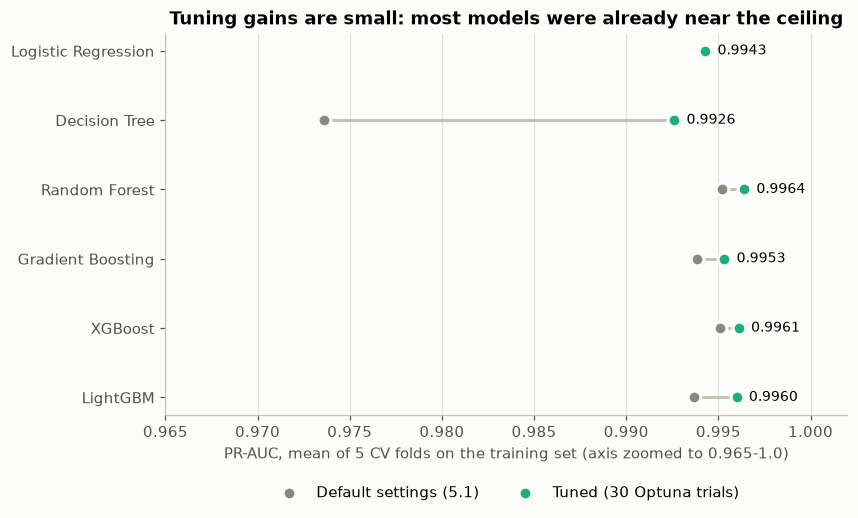

In [55]:
# Dot plot: default (grey) vs tuned (green) per model. Dots, not bars, so a zoomed axis is fair.
plot_data = tuning_summary.iloc[::-1]
y_positions = np.arange(len(plot_data))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hlines(y_positions, plot_data["default_pr_auc"], plot_data["tuned_pr_auc"],
          color="#c3c2b7", linewidth=2, zorder=1)
ax.scatter(plot_data["default_pr_auc"], y_positions, s=70, color=COLOR_RAW,
           edgecolor="#fcfcfb", linewidth=2, zorder=2, label="Default settings (5.1)")
ax.scatter(plot_data["tuned_pr_auc"], y_positions, s=70, color=COLOR_ENGINEERED,
           edgecolor="#fcfcfb", linewidth=2, zorder=3, label=f"Tuned ({N_TRIALS} Optuna trials)")
for y_pos, value in zip(y_positions, plot_data["tuned_pr_auc"]):
    ax.annotate(f"{value:.4f}", (value, y_pos), xytext=(8, 0), textcoords="offset points",
                va="center", fontsize=9)

ax.set_yticks(y_positions, plot_data.index)
ax.set_xlim(0.965, 1.002)
ax.set_xlabel("PR-AUC, mean of 5 CV folds on the training set (axis zoomed to 0.965-1.0)")
ax.set_title("Tuning gains are small: most models were already near the ceiling")
ax.grid(axis="y", visible=False)
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=2)

fig.savefig(FIGURES_DIR / "10_tuning_gains.png")
plt.show()

**Insight:** Only the Decision Tree gains meaningfully (PR-AUC 0.974 to 0.993): Optuna limited it to depth 5 with at least 43 rows per leaf, which removed its overfitting (training PR-AUC fell from 1.000 to 0.995 while validation rose). The ensembles gain 0.001-0.002, smaller than their fold-to-fold spread (0.002-0.004), so those gains are within noise; for Logistic Regression tuning found nothing better than the default (the two dots overlap). After tuning, Random Forest (0.9964), XGBoost (0.9961), LightGBM (0.9960) and Gradient Boosting (0.9953) are all within one fold standard deviation of each other, so cross-validation alone cannot pick a winner; the final choice needs other criteria such as simplicity, speed and explainability. Every run is logged in MLflow (`fraud-detection-tuning` experiment, one parent run per model with 30 child runs).

### 5.3 Final model choice

Cross-validation cannot separate the four tuned ensembles (all within one fold standard deviation), so the choice rests on other criteria. **Tuned LightGBM** goes forward:

- **Performance:** tied with the best (CV PR-AUC 0.9960 vs 0.9964 for Random Forest, well within the 0.003 fold spread).
- **Robustness:** the best model when the balance information is removed (0.662 on type + amount only vs 0.514 for Random Forest, 5.1), a hint that it degrades more gracefully on messier, real-world data.
- **Practicality:** the fastest ensemble to train, fast SHAP explanations for Section 8, and a small saved file for the API.

Only this one model is scored on the test set in Section 6, so the test set stays a one-time, honest check rather than a second round of model selection.

In [56]:
FINAL_MODEL_NAME = "LightGBM"

# The complete pipeline (feature class + one-hot encoding + tuned LightGBM), not yet fitted.
# Section 6 fits it on the full training set and scores it once on the test set.
final_pipeline = build_pipeline_for(tuned_model(FINAL_MODEL_NAME), "all features",
                                    scale=MODELS[FINAL_MODEL_NAME][1])
print("Steps:", [name for name, _ in final_pipeline.steps])
print("Tuned settings:", describe_settings(studies[FINAL_MODEL_NAME].best_params))

Steps: ['preprocess', 'model']
Tuned settings: n_estimators=450, learning_rate=0.149, num_leaves=33, min_child_samples=47, subsample=0.82, colsample_bytree=0.641, reg_lambda=0.0696


## 6. Evaluation

Precision, recall, F1, ROC-AUC, PR-AUC and the confusion matrix on the held-out test set, with ROC and precision-recall curves.

## 7. Financial impact

Explicit cost assumptions, the cost-minimising threshold, losses and savings with vs without the model, and a sensitivity table.

## 8. Explainability (SHAP)

Which features drive the model's fraud predictions, explained in business language.

## 9. Saving the final pipeline

Save the full Pipeline (features + encoding + classifier) to `model/fraud_model.joblib` and check that it reloads and predicts on raw columns.

## 10. Conclusions

Direct answers to the three business questions, limitations of the data, and next steps.